In [25]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("🚀 Libraries imported successfully!")
print(f"📱 PyTorch version: {torch.__version__}")
print(f"🔥 CUDA available: {torch.cuda.is_available()}")

🚀 Libraries imported successfully!
📱 PyTorch version: 2.6.0+cu124
🔥 CUDA available: True


In [26]:
class SupplyChainDataGenerator:
    def __init__(self, start_date="2022-01-01", end_date="2024-12-31"):
        self.start_date = datetime.strptime(start_date, "%Y-%m-%d")
        self.end_date = datetime.strptime(end_date, "%Y-%m-%d")
        self.date_range = pd.date_range(self.start_date, self.end_date, freq='D')
        
        self.products = {
            'electronics': {'base_demand': 45, 'volatility': 0.35, 'seasonality': 1.4},
            'clothing': {'base_demand': 75, 'volatility': 0.45, 'seasonality': 1.6},
            'groceries': {'base_demand': 180, 'volatility': 0.25, 'seasonality': 0.9},
            'books': {'base_demand': 25, 'volatility': 0.30, 'seasonality': 1.1},
            'home_goods': {'base_demand': 35, 'volatility': 0.40, 'seasonality': 1.2},
            'sports': {'base_demand': 30, 'volatility': 0.50, 'seasonality': 1.3},
            'beauty': {'base_demand': 40, 'volatility': 0.35, 'seasonality': 1.1},
            'automotive': {'base_demand': 15, 'volatility': 0.25, 'seasonality': 0.8},
            'toys': {'base_demand': 35, 'volatility': 0.55, 'seasonality': 1.8},
            'pharmacy': {'base_demand': 50, 'volatility': 0.20, 'seasonality': 0.9}
        }
        
        self.outlet_types = {
            'shopping_mall': {'size_factor': 2.5, 'product_variety': 0.9},
            'departmental_store': {'size_factor': 1.8, 'product_variety': 0.8},
            'bazaar_shop': {'size_factor': 1.2, 'product_variety': 0.6},
            'neighborhood_shop': {'size_factor': 1.0, 'product_variety': 0.5},
            'village_store': {'size_factor': 0.6, 'product_variety': 0.4}
        }
        
        self.regions = ['dhaka', 'chittagong', 'sylhet', 'rajshahi', 'khulna', 'barisal', 'rangpur', 'mymensingh']
        
        self.bd_events = {
            'eid_ul_fitr': {'probability': 0.02, 'demand_boost': 2.5},
            'eid_ul_adha': {'probability': 0.015, 'demand_boost': 2.0},
            'ramadan': {'probability': 0.08, 'demand_boost': 0.7},
            'hartal': {'probability': 0.03, 'demand_boost': 0.3},
            'heavy_monsoon': {'probability': 0.15, 'demand_boost': 0.6},
            'load_shedding': {'probability': 0.2, 'demand_boost': 0.8}
        }
        
        np.random.seed(42)
    
    def get_bd_season(self, month):
        seasons = {
            (12, 1, 2): 'sheet',
            (3, 4): 'basanta',
            (5, 6): 'grishma',
            (7, 8): 'borsha',
            (9, 10): 'sharat',
            (11,): 'hemanta'
        }
        for months, season in seasons.items():
            if month in months:
                return season
        return 'hemanta'
    
    def generate_seasonal_factor(self, date, product_id):
        day_of_year = date.timetuple().tm_yday
        month = date.month
        base_seasonal = self.products[product_id]['seasonality']
        seasonal = 1 + (base_seasonal - 1) * 0.4 * np.sin(2 * np.pi * day_of_year / 365)
        
        if product_id == 'clothing' and month in [10,11,12,1]:
            seasonal *= 1.4
        elif product_id == 'electronics' and month in [11,12]:
            seasonal *= 1.6
        elif product_id in ['groceries','toys'] and month in [4,11]:
            seasonal *= 1.5
        
        return max(0.3, seasonal)
    
    def _pick_compact_event(self, daily_events):
        event_priority = ['eid_ul_fitr', 'eid_ul_adha', 'ramadan', 'hartal', 'heavy_monsoon', 'load_shedding']
        for event in event_priority:
            if daily_events.get(event):
                if 'eid' in event:
                    return 'eid'
                return event.replace('_', '')
        return 'none'
    
    def generate_outlet_dataset(self, num_outlets=30):
        outlet_data = []
        outlet_types_list = list(self.outlet_types.keys())
        products_list = list(self.products.keys())
        
        outlet_info = {}
        for i in range(num_outlets):
            outlet_id = f"outlet_{i+1:03d}"
            outlet_type = np.random.choice(outlet_types_list)
            region = np.random.choice(self.regions)
            variety_rate = self.outlet_types[outlet_type]['product_variety']
            sells_products = {p for p in products_list if np.random.random() < variety_rate}
            while len(sells_products) < 2:
                sells_products.add(np.random.choice(products_list))
            
            econ = 'high' if region in ['dhaka','chittagong'] else 'medium' if region in ['sylhet','rajshahi'] else 'low'
            outlet_info[outlet_id] = {
                'outlet_type': outlet_type,
                'region': region,
                'economic_zone': econ,
                'sells_products': sells_products
            }
        
        region_factors = {
            'dhaka': 1.5, 'chittagong': 1.3, 'sylhet': 1.1, 'rajshahi': 1.0,
            'khulna': 0.9, 'barisal': 0.8, 'rangpur': 0.8, 'mymensingh': 0.8
        }
        
        for date in self.date_range:
            daily_events = {ev: (1 if np.random.random() < cfg['probability'] else 0) 
                            for ev, cfg in self.bd_events.items()}
            event_label = self._pick_compact_event(daily_events)
            
            day_of_week = date.weekday()
            is_weekend = int(day_of_week in [4, 5])
            bd_season = self.get_bd_season(date.month)
            
            for outlet_id, info in outlet_info.items():
                outlet_type = info['outlet_type']
                region = info['region']
                econ = info['economic_zone']
                sells_products = info['sells_products']
                size_factor = self.outlet_types[outlet_type]['size_factor']
                region_factor = region_factors.get(region, 1.0)
                
                for product_id in products_list:
                    if product_id in sells_products:
                        base_demand = self.products[product_id]['base_demand']
                        volatility = self.products[product_id]['volatility']
                        seasonal_factor = self.generate_seasonal_factor(date, product_id)
                        
                        event_factor = 1.0
                        if event_label == 'eid' and product_id in ['clothing','toys','electronics']:
                            event_factor = 2.0
                        elif event_label == 'ramadan' and product_id == 'groceries':
                            event_factor = 1.4
                        elif event_label == 'hartal':
                            event_factor = 0.4
                        elif event_label in ['heavymonsoon', 'monsoon']:
                            event_factor = 0.7
                        elif event_label in ['loadshedding', 'shedding']:
                            event_factor = 0.8
                        
                        weekend_factor = 1.4 if is_weekend else 1.0
                        
                        weekly_demand = (base_demand * size_factor * region_factor * seasonal_factor *
                                         event_factor * weekend_factor * 7 * np.random.normal(1, volatility))
                        weekly_demand = max(0, int(weekly_demand))
                    else:
                        weekly_demand = 0
                    
                    outlet_category = f"{outlet_type}_{econ}"
                    
                    outlet_data.append({
                        'date': date,
                        'outlet_id': outlet_id,
                        'product_id': product_id,
                        'outlet_category': outlet_category,
                        'region': region,
                        'bd_season': bd_season,
                        'is_weekend': is_weekend,
                        'event': event_label,
                        'economic_zone': econ,
                        'next_7_days_demand': weekly_demand
                    })
        
        df = pd.DataFrame(outlet_data)
        for c in ['outlet_category', 'region', 'bd_season', 'event', 'economic_zone', 'product_id']:
            df[c] = df[c].astype('category')
        return df

    def generate_warehouse_dataset(self, outlet_df):
        warehouse_data = []
        products_list = list(self.products.keys())
        inventory_levels = {prod: np.random.randint(8000, 20000) for prod in products_list}
        reliability_map = {'high': 1.2, 'medium': 1.0, 'low': 0.7}
        
        for date in self.date_range:
            daily_outlet_data = outlet_df[outlet_df['date'] == date]
            daily_events = {ev: (1 if np.random.random() < cfg['probability'] else 0) 
                            for ev, cfg in self.bd_events.items()}
            event_label = self._pick_compact_event(daily_events)
            
            is_weekend = int(date.weekday() in [4, 5])
            bd_season = self.get_bd_season(date.month)
            
            for product_id in products_list:
                product_data = daily_outlet_data[daily_outlet_data['product_id'] == product_id]
                expected_7_day_demand = int(product_data['next_7_days_demand'].sum()) if not product_data.empty else 0
                
                current_inventory = inventory_levels[product_id]
                
                inbound = 0
                shipment_prob = 0.25
                if daily_events.get('hartal'):
                    shipment_prob *= 0.1
                if daily_events.get('heavy_monsoon'):
                    shipment_prob *= 0.3
                if is_weekend:
                    shipment_prob *= 0.6
                    
                if np.random.random() < shipment_prob:
                    inbound = int(expected_7_day_demand * np.random.uniform(3, 7))
                
                new_inventory = max(0, current_inventory + inbound)
                inventory_levels[product_id] = new_inventory
                
                safety_stock = expected_7_day_demand * 0.5
                optimal_inventory = int(expected_7_day_demand + safety_stock)
                max_storage_capacity = np.random.randint(20000, 50000)
                
                supplier_reliability = np.random.choice(['high','medium','low'])
                supplier_capacity_index = round(np.random.uniform(0.7, 1.5), 2)
                supplier_lead_time = np.random.randint(2, 14)
                allocation_ratio = round(np.random.uniform(0.3, 1.0), 2)
                
                disruption_index = 1.0
                if event_label == 'hartal':
                    disruption_index *= 0.5
                elif event_label in ['heavymonsoon', 'monsoon']:
                    disruption_index *= 0.7
                elif event_label in ['loadshedding', 'shedding']:
                    disruption_index *= 0.85
                disruption_index *= round(np.random.uniform(0.85, 1.05), 3)
                
                supplier_reliability_val = reliability_map[supplier_reliability]
                transport_cost_index = round(np.random.uniform(0.8, 1.5) * (1.0 + (1 - disruption_index) * 0.2), 3)
                
                buffer_factor = 1.1 if supplier_reliability == 'high' else 1.0
                raw_feasible = int(expected_7_day_demand * supplier_capacity_index * allocation_ratio * 
                                 supplier_reliability_val * buffer_factor * disruption_index)
                feasible_max_supply = max(0, min(max_storage_capacity, raw_feasible))
                
                if expected_7_day_demand == 0:
                    feasible_max_supply = int(min(max_storage_capacity, supplier_capacity_index * allocation_ratio * 1000 * disruption_index))
                
                warehouse_data.append({
                    'date': date,
                    'product_id': product_id,
                    'bd_season': bd_season,
                    'is_weekend': is_weekend,
                    'event': event_label,
                    'current_inventory': current_inventory,
                    'inbound_shipment': inbound,
                    'supplier_reliability': supplier_reliability,
                    'supplier_capacity_index': supplier_capacity_index,
                    'supplier_lead_time': supplier_lead_time,
                    'allocation_ratio': allocation_ratio,
                    'disruption_index': round(disruption_index, 3),
                    'transport_cost_index': transport_cost_index,
                    'max_storage_capacity': max_storage_capacity,
                    'optimal_inventory_level': optimal_inventory,
                    'feasible_max_supply': int(feasible_max_supply)
                })
        
        df = pd.DataFrame(warehouse_data)
        for c in ['product_id', 'bd_season', 'event', 'supplier_reliability']:
            df[c] = df[c].astype('category')
        return df

    def generate_datasets(self, num_outlets=30):
        outlet_df = self.generate_outlet_dataset(num_outlets)
        warehouse_df = self.generate_warehouse_dataset(outlet_df)
        return outlet_df, warehouse_df

print("✅ SupplyChainDataGenerator class defined!")

✅ SupplyChainDataGenerator class defined!


In [27]:
# Generate datasets
print("🔄 Generating Bangladesh Supply Chain Datasets...")
print("=" * 60)

generator = SupplyChainDataGenerator(start_date="2022-01-01", end_date="2024-12-31")
outlet_df, warehouse_df = generator.generate_datasets(num_outlets=30)

# Save datasets
outlet_df.to_csv('bd_outlet_compact.csv', index=False)
warehouse_df.to_csv('bd_warehouse_central.csv', index=False)

print(f"📅 Date Range: 2022-01-01 to 2024-12-31")
print(f"🏪 Number of Outlets: 30")
print(f"🏭 Number of Warehouses: 1 (Central)")
print(f"📦 Product Categories: {len(generator.products)}")
print()

# OUTLET DATASET ANALYSIS
print("📊 OUTLET DATASET ANALYSIS")
print("-" * 40)
print(f"📏 Dataset Shape: {outlet_df.shape}")
print(f"🎯 Target Column: 'next_7_days_demand'")
print(f"📋 All Features: {list(outlet_df.columns)}")
print()

print("📈 Target Variable Statistics:")
target_stats = outlet_df['next_7_days_demand'].describe()
print(target_stats)
print()

print("🏷️ Categorical Features Distribution:")
categorical_cols = ['product_id', 'outlet_category', 'region', 'bd_season', 'event', 'economic_zone']
for col in categorical_cols[:4]:  # Show first 4 to save space
    print(f"{col}: {outlet_df[col].nunique()} unique values")
    print(f"  Most common: {outlet_df[col].value_counts().head(3).to_dict()}")
print()

# WAREHOUSE DATASET ANALYSIS
print("📊 WAREHOUSE DATASET ANALYSIS")
print("-" * 40)
print(f"📏 Dataset Shape: {warehouse_df.shape}")
print(f"🎯 Target Columns: 'optimal_inventory_level', 'feasible_max_supply'")
print(f"📋 All Features: {list(warehouse_df.columns)}")
print()

print("📈 Target Variables Statistics:")
for target in ['optimal_inventory_level', 'feasible_max_supply']:
    print(f"\n{target}:")
    print(warehouse_df[target].describe())

print("\n✅ Dataset generation and analysis complete!")

🔄 Generating Bangladesh Supply Chain Datasets...
📅 Date Range: 2022-01-01 to 2024-12-31
🏪 Number of Outlets: 30
🏭 Number of Warehouses: 1 (Central)
📦 Product Categories: 10

📊 OUTLET DATASET ANALYSIS
----------------------------------------
📏 Dataset Shape: (328800, 10)
🎯 Target Column: 'next_7_days_demand'
📋 All Features: ['date', 'outlet_id', 'product_id', 'outlet_category', 'region', 'bd_season', 'is_weekend', 'event', 'economic_zone', 'next_7_days_demand']

📈 Target Variable Statistics:
count    328800.000000
mean        395.595970
std         740.921751
min           0.000000
25%           0.000000
50%         153.000000
75%         470.000000
max       14235.000000
Name: next_7_days_demand, dtype: float64

🏷️ Categorical Features Distribution:
product_id: 10 unique values
  Most common: {'automotive': 32880, 'beauty': 32880, 'books': 32880}
outlet_category: 13 unique values
  Most common: {'village_store_low': 65760, 'neighborhood_shop_low': 54800, 'shopping_mall_medium': 54800}


In [28]:
class SupplyChainPreprocessor:
    def __init__(self):
        self.outlet_df = None
        self.warehouse_df = None
        self.outlet_encoders = {}
        self.warehouse_encoders = {}
        self.scalers = {}
        self.target_scalers = {}
        self.feature_columns = {}

    def load_data(self, outlet_path='bd_outlet_compact.csv', warehouse_path='bd_warehouse_central.csv'):
        self.outlet_df = pd.read_csv(outlet_path)
        self.warehouse_df = pd.read_csv(warehouse_path)
        self.outlet_df['date'] = pd.to_datetime(self.outlet_df['date'])
        self.warehouse_df['date'] = pd.to_datetime(self.warehouse_df['date'])

    def create_temporal_features(self, df):
        df = df.copy()
        df['year'] = df['date'].dt.year
        df['month'] = df['date'].dt.month
        df['day'] = df['date'].dt.day
        df['dayofweek'] = df['date'].dt.dayofweek
        df['quarter'] = df['date'].dt.quarter
        df['week_of_year'] = df['date'].dt.isocalendar().week
        
        start_date = pd.to_datetime('2022-01-01')
        df['days_since_start'] = (df['date'] - start_date).dt.days
        df['days_since_start_norm'] = df['days_since_start'] / 1000
        
        # Cyclical features
        df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
        df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
        df['dayofweek_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
        df['dayofweek_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)
        
        # Season indicators
        df['is_winter'] = df['month'].isin([12, 1, 2]).astype(int)
        df['is_summer'] = df['month'].isin([5, 6, 7, 8]).astype(int)
        df['is_festival_season'] = df['month'].isin([4, 11, 12]).astype(int)
        
        return df

    def create_warehouse_features(self, df):
        df = df.copy()
        df['inventory_ratio'] = np.clip(df['current_inventory'] / np.maximum(df['max_storage_capacity'], 1), 0, 1)
        df['inbound_ratio'] = np.clip(df['inbound_shipment'] / np.maximum(df['current_inventory'], 1), 0, 10)
        df['efficiency_score'] = df['allocation_ratio'] * df['disruption_index']
        df['supply_reliability'] = (df['supplier_reliability'] == 'high').astype(int) * df['supplier_capacity_index']
        df['low_inventory'] = (df['current_inventory'] < df['optimal_inventory_level'] * 0.8).astype(int)
        df['high_lead_time'] = (df['supplier_lead_time'] > 7).astype(int)
        df['disruption_risk'] = (df['disruption_index'] < 0.8).astype(int)
        
        df['capacity_category'] = pd.cut(df['supplier_capacity_index'], 
                                       bins=[0, 0.8, 1.2, 2.0], 
                                       labels=['low', 'medium', 'high']).astype(str)
        return df

    def prepare_outlet_data(self, test_size=0.2, val_size=0.1):
        print("🔄 Preparing Outlet Data...")
        df = self.create_temporal_features(self.outlet_df)
        
        # Remove outliers
        demand_99 = df['next_7_days_demand'].quantile(0.99)
        demand_1 = df['next_7_days_demand'].quantile(0.01)
        original_size = len(df)
        df = df[(df['next_7_days_demand'] >= demand_1) & (df['next_7_days_demand'] <= demand_99)]
        print(f"📈 Outlier removal: {original_size} → {len(df)} rows")

        # Encode categoricals
        categorical_cols = ['outlet_id', 'product_id', 'outlet_category', 'region', 'bd_season', 'event', 'economic_zone']
        
        for col in categorical_cols:
            le = LabelEncoder()
            df[col + '_encoded'] = le.fit_transform(df[col].astype(str))
            self.outlet_encoders[col] = le
            
            # Target mean encoding
            mean_target = df.groupby(col)['next_7_days_demand'].mean()
            df[col + '_target_mean'] = df[col].map(mean_target)

        numerical_features = [
            'days_since_start_norm', 'month', 'dayofweek', 'quarter',
            'month_sin', 'month_cos', 'dayofweek_sin', 'dayofweek_cos',
            'is_weekend', 'is_winter', 'is_summer', 'is_festival_season'
        ]
        
        categorical_features = [col + '_encoded' for col in categorical_cols]
        target_mean_features = [col + '_target_mean' for col in categorical_cols]
        
        all_features = numerical_features + categorical_features + target_mean_features
        self.feature_columns['outlet'] = all_features
        
        print(f"🎯 Total Features: {len(all_features)}")
        print(f"   - Numerical: {len(numerical_features)}")
        print(f"   - Categorical Encoded: {len(categorical_features)}")
        print(f"   - Target Mean Encoded: {len(target_mean_features)}")
        
        X = df[all_features].values
        y = df['next_7_days_demand'].values
        
        # Target transformation
        y_sqrt = np.sqrt(np.maximum(y, 0))
        target_scaler = MinMaxScaler()
        y_scaled = target_scaler.fit_transform(y_sqrt.reshape(-1, 1)).flatten()
        self.target_scalers['outlet'] = {'scaler': target_scaler, 'transform': 'sqrt'}

        # Feature scaling
        imputer = SimpleImputer(strategy='median')
        X = imputer.fit_transform(X)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        self.scalers['outlet'] = {'scaler': scaler, 'imputer': imputer}

        # Split data
        X_temp, X_test, y_temp, y_test = train_test_split(X_scaled, y_scaled, test_size=test_size, random_state=42)
        val_size_adj = val_size / (1 - test_size)
        X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=val_size_adj, random_state=42)

        print(f"📊 Data Split Shapes:")
        print(f"   - Train: {X_train.shape}")
        print(f"   - Validation: {X_val.shape}")
        print(f"   - Test: {X_test.shape}")

        return {
            'X_train': torch.FloatTensor(X_train),
            'X_val': torch.FloatTensor(X_val),
            'X_test': torch.FloatTensor(X_test),
            'y_train': torch.FloatTensor(y_train).unsqueeze(1),
            'y_val': torch.FloatTensor(y_val).unsqueeze(1),
            'y_test': torch.FloatTensor(y_test).unsqueeze(1),
            'feature_names': all_features
        }

    def prepare_warehouse_data(self, test_size=0.2, val_size=0.1):
        print("\n🔄 Preparing Warehouse Data...")
        df = self.create_temporal_features(self.warehouse_df)
        df = self.create_warehouse_features(df)
        
        # Remove outliers
        original_size = len(df)
        for target in ['optimal_inventory_level', 'feasible_max_supply']:
            q99 = df[target].quantile(0.99)
            q1 = df[target].quantile(0.01)
            df = df[(df[target] >= q1) & (df[target] <= q99)]
        print(f"📈 Outlier removal: {original_size} → {len(df)} rows")

        # Encode categoricals
        categorical_cols = ['product_id', 'bd_season', 'event', 'supplier_reliability', 'capacity_category']
        
        for col in categorical_cols:
            le = LabelEncoder()
            df[col + '_encoded'] = le.fit_transform(df[col].astype(str))
            self.warehouse_encoders[col] = le

        numerical_features = [
            'days_since_start_norm', 'month', 'dayofweek',
            'month_sin', 'month_cos', 'dayofweek_sin', 'dayofweek_cos',
            'is_weekend', 'is_winter', 'is_summer', 'is_festival_season',
            'supplier_capacity_index', 'supplier_lead_time', 'allocation_ratio',
            'disruption_index', 'inventory_ratio', 'inbound_ratio',
            'efficiency_score', 'supply_reliability', 'low_inventory',
            'high_lead_time', 'disruption_risk'
        ]
        
        categorical_features = [col + '_encoded' for col in categorical_cols]
        all_features = numerical_features + categorical_features
        self.feature_columns['warehouse'] = all_features
        
        print(f"🎯 Total Features: {len(all_features)}")
        print(f"   - Numerical: {len(numerical_features)}")
        print(f"   - Categorical Encoded: {len(categorical_features)}")
        
        X = df[all_features].values
        y = df[['optimal_inventory_level', 'feasible_max_supply']].values

        # Target transformation
        y_sqrt = np.sqrt(np.maximum(y, 0))
        target_scalers = {}
        y_scaled = np.zeros_like(y_sqrt)
        
        for i, target_name in enumerate(['optimal_inventory', 'feasible_supply']):
            scaler = MinMaxScaler()
            y_scaled[:, i] = scaler.fit_transform(y_sqrt[:, i].reshape(-1, 1)).flatten()
            target_scalers[target_name] = {'scaler': scaler, 'transform': 'sqrt'}
        
        self.target_scalers['warehouse'] = target_scalers

        # Feature scaling
        imputer = SimpleImputer(strategy='median')
        X = imputer.fit_transform(X)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        self.scalers['warehouse'] = {'scaler': scaler, 'imputer': imputer}

        # Split data
        X_temp, X_test, y_temp, y_test = train_test_split(X_scaled, y_scaled, test_size=test_size, random_state=42)
        val_size_adj = val_size / (1 - test_size)
        X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=val_size_adj, random_state=42)

        print(f"📊 Data Split Shapes:")
        print(f"   - Train: {X_train.shape}")
        print(f"   - Validation: {X_val.shape}")
        print(f"   - Test: {X_test.shape}")

        return {
            'X_train': torch.FloatTensor(X_train),
            'X_val': torch.FloatTensor(X_val),
            'X_test': torch.FloatTensor(X_test),
            'y_train': torch.FloatTensor(y_train),
            'y_val': torch.FloatTensor(y_val),
            'y_test': torch.FloatTensor(y_test),
            'feature_names': all_features,
            'target_names': ['optimal_inventory_level', 'feasible_max_supply']
        }

    def inverse_transform_target(self, y_transformed, model_type, target_name=None):
        if model_type == 'outlet':
            scaler_info = self.target_scalers['outlet']
            y_sqrt = scaler_info['scaler'].inverse_transform(y_transformed.reshape(-1, 1)).flatten()
            return np.maximum(y_sqrt ** 2, 0)
        elif model_type == 'warehouse':
            scaler_info = self.target_scalers['warehouse'][target_name]
            y_sqrt = scaler_info['scaler'].inverse_transform(y_transformed.reshape(-1, 1)).flatten()
            return np.maximum(y_sqrt ** 2, 0)

print("✅ SupplyChainPreprocessor class defined!")

✅ SupplyChainPreprocessor class defined!


In [29]:
# Initialize preprocessor and prepare data
preprocessor = SupplyChainPreprocessor()
preprocessor.load_data()

# Prepare outlet data
outlet_splits = preprocessor.prepare_outlet_data()

# Prepare warehouse data
warehouse_splits = preprocessor.prepare_warehouse_data()

print("\n" + "="*60)
print("📋 FINAL MATRIX SHAPES SUMMARY")
print("="*60)

print("\n🏪 OUTLET MODEL DATA:")
for split_name, tensor in outlet_splits.items():
    if isinstance(tensor, torch.Tensor):
        print(f"   {split_name:10s}: {tuple(tensor.shape)}")

print("\n🏭 WAREHOUSE MODEL DATA:")
for split_name, tensor in warehouse_splits.items():
    if isinstance(tensor, torch.Tensor):
        print(f"   {split_name:10s}: {tuple(tensor.shape)}")

print(f"\n✅ Data preprocessing complete!")
print(f"🔥 Using device: {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

🔄 Preparing Outlet Data...
📈 Outlier removal: 328800 → 325516 rows
🎯 Total Features: 26
   - Numerical: 12
   - Categorical Encoded: 7
   - Target Mean Encoded: 7
📊 Data Split Shapes:
   - Train: (227860, 26)
   - Validation: (32552, 26)
   - Test: (65104, 26)

🔄 Preparing Warehouse Data...
📈 Outlier removal: 10960 → 10525 rows
🎯 Total Features: 27
   - Numerical: 22
   - Categorical Encoded: 5
📊 Data Split Shapes:
   - Train: (7367, 27)
   - Validation: (1053, 27)
   - Test: (2105, 27)

📋 FINAL MATRIX SHAPES SUMMARY

🏪 OUTLET MODEL DATA:
   X_train   : (227860, 26)
   X_val     : (32552, 26)
   X_test    : (65104, 26)
   y_train   : (227860, 1)
   y_val     : (32552, 1)
   y_test    : (65104, 1)

🏭 WAREHOUSE MODEL DATA:
   X_train   : (7367, 27)
   X_val     : (1053, 27)
   X_test    : (2105, 27)
   y_train   : (7367, 2)
   y_val     : (1053, 2)
   y_test    : (2105, 2)

✅ Data preprocessing complete!
🔥 Using device: cuda


In [30]:
class OutletNet(nn.Module):
    def __init__(self, input_size, dropout_rate=0.2):
        super().__init__()
        
        self.backbone = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate/2),
            
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.backbone(x)


class WarehouseNet(nn.Module):
    def __init__(self, input_size, dropout_rate=0.2):
        super().__init__()
        
        self.shared = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )
        
        self.head1 = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
        
        self.head2 = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        shared_features = self.shared(x)
        out1 = self.head1(shared_features)
        out2 = self.head2(shared_features)
        return torch.cat([out1, out2], dim=1)

print("✅ Neural Network models defined!")

✅ Neural Network models defined!


In [31]:
class ModelTrainer:
    def __init__(self, model, device='cpu', model_name="Model"):
        self.model = model
        self.device = device
        self.model_name = model_name
        self.model.to(device)
        self.train_losses = []
        self.val_losses = []

    def train_model(self, train_data, val_data, epochs=100, batch_size=512, lr=0.001, patience=15, verbose=True):
        train_dataset = TensorDataset(train_data['X'], train_data['y'])
        val_dataset = TensorDataset(val_data['X'], val_data['y'])
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        
        optimizer = optim.Adam(self.model.parameters(), lr=lr, weight_decay=1e-4)
        criterion = nn.MSELoss()
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=8, verbose=False)
        
        best_val_loss = float('inf')
        patience_counter = 0
        
        print(f"\n🚀 Training {self.model_name}...")
        print(f"📊 Batch size: {batch_size}, Learning rate: {lr}, Max epochs: {epochs}")
        
        for epoch in range(epochs):
            # Training
            self.model.train()
            train_loss = 0
            for batch_X, batch_y in train_loader:
                batch_X, batch_y = batch_X.to(self.device), batch_y.to(self.device)
                
                optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
                
                train_loss += loss.item()
            
            # Validation
            self.model.eval()
            val_loss = 0
            with torch.no_grad():
                for batch_X, batch_y in val_loader:
                    batch_X, batch_y = batch_X.to(self.device), batch_y.to(self.device)
                    outputs = self.model(batch_X)
                    loss = criterion(outputs, batch_y)
                    val_loss += loss.item()
            
            avg_train_loss = train_loss / len(train_loader)
            avg_val_loss = val_loss / len(val_loader)
            
            # Store losses for plotting
            self.train_losses.append(avg_train_loss)
            self.val_losses.append(avg_val_loss)
            
            scheduler.step(avg_val_loss)
            
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                patience_counter = 0
                torch.save(self.model.state_dict(), f'best_{self.model_name.lower().replace(" ", "_")}.pth')
            else:
                patience_counter += 1
            
            if verbose and epoch % 20 == 0:
                print(f"Epoch {epoch:3d}: Train={avg_train_loss:.6f}, Val={avg_val_loss:.6f}")
            
            if patience_counter >= patience:
                if verbose:
                    print(f"⏹️ Early stopping at epoch {epoch}")
                break
        
        self.model.load_state_dict(torch.load(f'best_{self.model_name.lower().replace(" ", "_")}.pth'))
        if verbose:
            print(f"✅ Training completed! Best validation loss: {best_val_loss:.6f}")

    def plot_training_history(self):
        """Plot training and validation loss"""
        plt.figure(figsize=(10, 6))
        plt.plot(self.train_losses, label='Training Loss', linewidth=2)
        plt.plot(self.val_losses, label='Validation Loss', linewidth=2)
        plt.title(f'{self.model_name} - Training History', fontsize=14, fontweight='bold')
        plt.xlabel('Epoch')
        plt.ylabel('Loss (MSE)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def evaluate_model(self, test_data, preprocessor, model_type, target_names=None):
        self.model.eval()
        
        with torch.no_grad():
            test_X = test_data['X'].to(self.device)
            test_y = test_data['y'].to(self.device)
            predictions_scaled = self.model(test_X).cpu().numpy()
            actual_scaled = test_y.cpu().numpy()
        
        if model_type == 'outlet':
            predictions = preprocessor.inverse_transform_target(predictions_scaled.flatten(), 'outlet')
            actual = preprocessor.inverse_transform_target(actual_scaled.flatten(), 'outlet')
            
            mae = mean_absolute_error(actual, predictions)
            mse = mean_squared_error(actual, predictions)
            rmse = np.sqrt(mse)
            r2 = r2_score(actual, predictions)
            
            return {'mae': mae, 'mse': mse, 'rmse': rmse, 'r2': r2, 'predictions': predictions, 'actual': actual}
        
        else:  # warehouse
            target_mappings = ['optimal_inventory', 'feasible_supply']
            results = {}
            
            for i, (target_name, mapping) in enumerate(zip(target_names, target_mappings)):
                predictions = preprocessor.inverse_transform_target(
                    predictions_scaled[:, i], 'warehouse', mapping
                )
                actual = preprocessor.inverse_transform_target(
                    actual_scaled[:, i], 'warehouse', mapping
                )
                
                mae = mean_absolute_error(actual, predictions)
                mse = mean_squared_error(actual, predictions)
                rmse = np.sqrt(mse)
                r2 = r2_score(actual, predictions)
                
                results[target_name] = {
                    'mae': mae, 'mse': mse, 'rmse': rmse, 'r2': r2, 
                    'predictions': predictions, 'actual': actual
                }
            
            return results

print("✅ ModelTrainer class with loss tracking defined!")

✅ ModelTrainer class with loss tracking defined!


🔥 Using device: cuda

🚀 Training Outlet Model...
📊 Batch size: 512, Learning rate: 0.001, Max epochs: 100
Epoch   0: Train=0.027842, Val=0.019186
Epoch  20: Train=0.006604, Val=0.004675
Epoch  40: Train=0.006448, Val=0.004511
Epoch  60: Train=0.006885, Val=0.004516
Epoch  80: Train=0.005511, Val=0.004148
✅ Training completed! Best validation loss: 0.004048


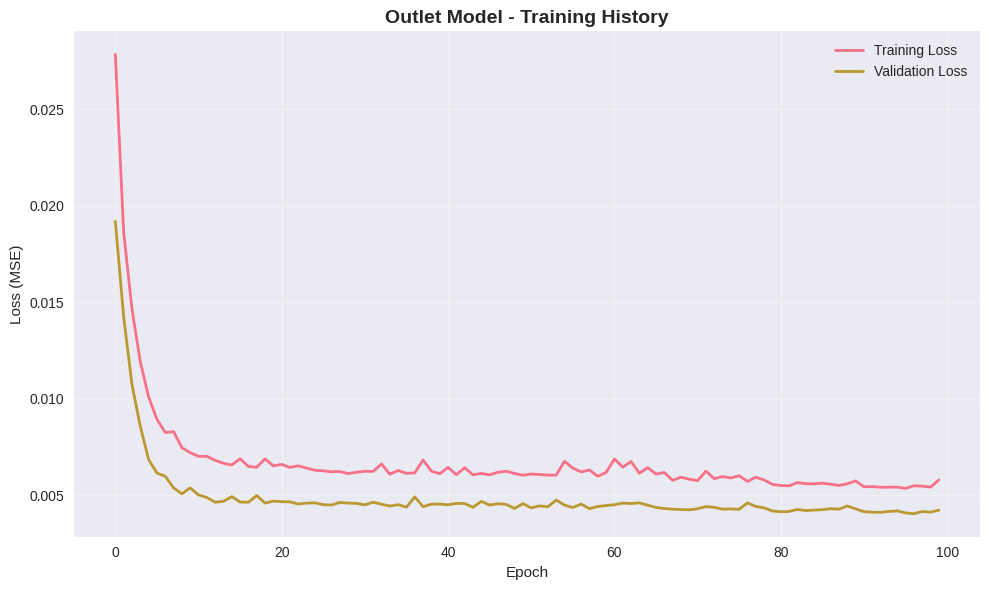

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔥 Using device: {device}")

# Train outlet model
outlet_model = OutletNet(outlet_splits['X_train'].shape[1])
outlet_trainer = ModelTrainer(outlet_model, device, "Outlet Model")

outlet_trainer.train_model(
    train_data={'X': outlet_splits['X_train'], 'y': outlet_splits['y_train']},
    val_data={'X': outlet_splits['X_val'], 'y': outlet_splits['y_val']},
    epochs=100, batch_size=512, lr=0.001, verbose=True
)

# Plot training history
outlet_trainer.plot_training_history()


🚀 Training Warehouse Model...
📊 Batch size: 256, Learning rate: 0.001, Max epochs: 100
Epoch   0: Train=0.056303, Val=0.038500
Epoch  20: Train=0.019205, Val=0.019594
Epoch  40: Train=0.010121, Val=0.008805
Epoch  60: Train=0.007796, Val=0.006831
Epoch  80: Train=0.007244, Val=0.006003
✅ Training completed! Best validation loss: 0.005869


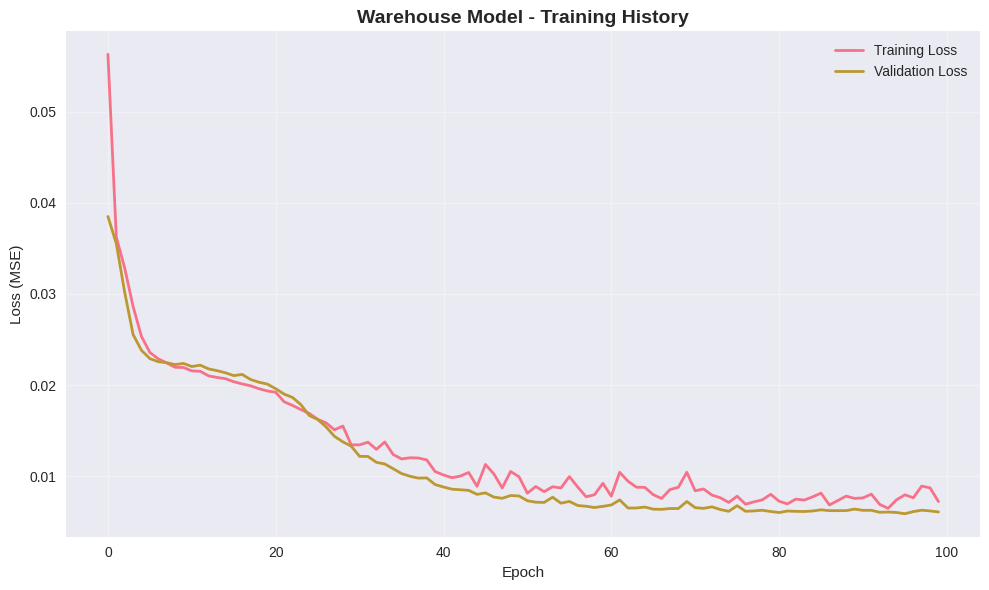

In [33]:
# Train warehouse model
warehouse_model = WarehouseNet(warehouse_splits['X_train'].shape[1])
warehouse_trainer = ModelTrainer(warehouse_model, device, "Warehouse Model")

warehouse_trainer.train_model(
    train_data={'X': warehouse_splits['X_train'], 'y': warehouse_splits['y_train']},
    val_data={'X': warehouse_splits['X_val'], 'y': warehouse_splits['y_val']},
    epochs=100, batch_size=256, lr=0.001, verbose=True
)

# Plot training history
warehouse_trainer.plot_training_history()

In [ ]:
print("\n" + "="*60)
print("📊 MODEL EVALUATION ON TEST SET")
print("="*60)

# Evaluate outlet model
outlet_results = outlet_trainer.evaluate_model(
    test_data={'X': outlet_splits['X_test'], 'y': outlet_splits['y_test']},
    preprocessor=preprocessor,
    model_type='outlet'
)

# Evaluate warehouse model
warehouse_results = warehouse_trainer.evaluate_model(
    test_data={'X': warehouse_splits['X_test'], 'y': warehouse_splits['y_test']},
    preprocessor=preprocessor,
    model_type='warehouse',
    target_names=warehouse_splits['target_names']
)

print("\n🏪 OUTLET MODEL TEST RESULTS:")
print(f"   R² Score: {outlet_results['r2']:.4f}")
print(f"   RMSE: {outlet_results['rmse']:,.2f}")
print(f"   MAE: {outlet_results['mae']:,.2f}")
print(f"   MSE: {outlet_results['mse']:,.2f}")

print("\n🏭 WAREHOUSE MODEL TEST RESULTS:")
for target_name, metrics in warehouse_results.items():
    print(f"\n   {target_name.upper()}:")
    print(f"     R² Score: {metrics['r2']:.4f}")
    print(f"     RMSE: {metrics['rmse']:,.2f}")
    print(f"     MAE: {metrics['mae']:,.2f}")
    print(f"     MSE: {metrics['mse']:,.2f}")

# Create visualization of results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Outlet predictions vs actual
axes[0].scatter(outlet_results['actual'], outlet_results['predictions'], alpha=0.6, s=20)
axes[0].plot([outlet_results['actual'].min(), outlet_results['actual'].max()], 
             [outlet_results['actual'].min(), outlet_results['actual'].max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Demand')
axes[0].set_ylabel('Predicted Demand')
axes[0].set_title(f'Outlet Model\nR² = {outlet_results["r2"]:.4f}')
axes[0].grid(True, alpha=0.3)

# Warehouse predictions vs actual - optimal inventory
target_1 = warehouse_results['optimal_inventory_level']
axes[1].scatter(target_1['actual'], target_1['predictions'], alpha=0.6, s=20, color='orange')
axes[1].plot([target_1['actual'].min(), target_1['actual'].max()], 
             [target_1['actual'].min(), target_1['actual'].max()], 'r--', lw=2)
axes[1].set_xlabel('Actual Optimal Inventory')
axes[1].set_ylabel('Predicted Optimal Inventory')
axes[1].set_title(f'Warehouse Model - Optimal Inventory\nR² = {target_1["r2"]:.4f}')
axes[1].grid(True, alpha=0.3)

# Warehouse predictions vs actual - feasible supply
target_2 = warehouse_results['feasible_max_supply']
axes[2].scatter(target_2['actual'], target_2['predictions'], alpha=0.6, s=20, color='green')
axes[2].plot([target_2['actual'].min(), target_2['actual'].max()], 
             [target_2['actual'].min(), target_2['actual'].max()], 'r--', lw=2)
axes[2].set_xlabel('Actual Feasible Supply')
axes[2].set_ylabel('Predicted Feasible Supply')
axes[2].set_title(f'Warehouse Model - Feasible Supply\nR² = {target_2["r2"]:.4f}')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Model evaluation complete!")


📊 MODEL EVALUATION ON TEST SET

🏪 OUTLET MODEL TEST RESULTS:
   R² Score: 0.8529
   RMSE: 210.45
   MAE: 98.90
   MSE: 44,290.97

🏭 WAREHOUSE MODEL TEST RESULTS:

   OPTIMAL_INVENTORY_LEVEL:
     R² Score: 0.8838
     RMSE: 4,971.70
     MAE: 3,087.19
     MSE: 24,717,844.00

   FEASIBLE_MAX_SUPPLY:
     R² Score: 0.8836
     RMSE: 2,084.58
     MAE: 1,268.92
     MSE: 4,345,494.00


In [37]:
# Add prediction methods to preprocessor
def predict(self, outlet_model, warehouse_model, outlet_sample, warehouse_sample, device='cpu'):
    predictions = {}
    
    # OUTLET PREDICTION
    outlet_features = self._build_outlet_features(outlet_sample)
    outlet_tensor = self._preprocess_features(outlet_features, 'outlet', device)
    
    outlet_model.eval()
    with torch.no_grad():
        outlet_pred_scaled = outlet_model(outlet_tensor).cpu().numpy().flatten()
        outlet_pred = self.inverse_transform_target(outlet_pred_scaled, 'outlet')
        predictions['outlet_demand'] = max(0, outlet_pred[0])
    
    # WAREHOUSE PREDICTION
    warehouse_features = self._build_warehouse_features(warehouse_sample)
    warehouse_tensor = self._preprocess_features(warehouse_features, 'warehouse', device)
    
    warehouse_model.eval()
    with torch.no_grad():
        warehouse_pred_scaled = warehouse_model(warehouse_tensor).cpu().numpy()[0]
        
        optimal_inv = self.inverse_transform_target(
            warehouse_pred_scaled[0:1], 'warehouse', 'optimal_inventory'
        )
        feasible_sup = self.inverse_transform_target(
            warehouse_pred_scaled[1:2], 'warehouse', 'feasible_supply'
        )
        
        predictions['optimal_inventory'] = max(0, optimal_inv[0])
        predictions['feasible_supply'] = max(0, feasible_sup[0])
    
    return predictions

def _build_outlet_features(self, sample):
    date = pd.to_datetime(sample['date'])
    
    # Temporal features
    days_since_start_norm = (date - pd.to_datetime('2022-01-01')).days / 1000
    month = date.month
    dayofweek = date.dayofweek
    quarter = date.quarter
    
    # Cyclical features
    month_sin = np.sin(2 * np.pi * month / 12)
    month_cos = np.cos(2 * np.pi * month / 12)
    dayofweek_sin = np.sin(2 * np.pi * dayofweek / 7)
    dayofweek_cos = np.cos(2 * np.pi * dayofweek / 7)
    
    # Season indicators
    is_winter = int(month in [12, 1, 2])
    is_summer = int(month in [5, 6, 7, 8])
    is_festival_season = int(month in [4, 11, 12])
    
    numerical_features = [
        days_since_start_norm, month, dayofweek, quarter,
        month_sin, month_cos, dayofweek_sin, dayofweek_cos,
        sample.get('is_weekend', 0), is_winter, is_summer, is_festival_season
    ]
    
    # Categorical features (encoded)
    categorical_mapping = {
        'outlet_id': sample.get('outlet_id', 'outlet_001'),
        'product_id': sample['product_id'],
        'outlet_category': sample.get('outlet_category', 'shopping_mall_high'),
        'region': sample['region'],
        'bd_season': sample.get('bd_season', 'grishma'),
        'event': sample.get('event', 'none'),
        'economic_zone': sample.get('economic_zone', 'high')
    }
    
    features = numerical_features.copy()
    
    for col in ['outlet_id', 'product_id', 'outlet_category', 'region', 'bd_season', 'event', 'economic_zone']:
        encoder = self.outlet_encoders[col]
        value = str(categorical_mapping[col])
        
        if value in encoder.classes_:
            encoded_val = encoder.transform([value])[0]
        else:
            encoded_val = 0
        features.append(encoded_val)
    
    # Target mean features (use reasonable defaults for new samples)
    target_means = []
    for col in ['outlet_id', 'product_id', 'outlet_category', 'region', 'bd_season', 'event', 'economic_zone']:
        # Use product-specific defaults
        if col == 'product_id':
            product_defaults = {
                'electronics': 120, 'clothing': 150, 'groceries': 300,
                'books': 50, 'home_goods': 80, 'sports': 70,
                'beauty': 90, 'automotive': 30, 'toys': 100, 'pharmacy': 110
            }
            target_means.append(product_defaults.get(sample['product_id'], 100))
        else:
            target_means.append(100)  # Default value
    
    features.extend(target_means)
    
    return np.array(features, dtype=np.float32)

def _build_warehouse_features(self, sample):
    date = pd.to_datetime(sample['date'])
    
    # Temporal features
    days_since_start_norm = (date - pd.to_datetime('2022-01-01')).days / 1000
    month = date.month
    dayofweek = date.dayofweek
    
    # Cyclical features
    month_sin = np.sin(2 * np.pi * month / 12)
    month_cos = np.cos(2 * np.pi * month / 12)
    dayofweek_sin = np.sin(2 * np.pi * dayofweek / 7)
    dayofweek_cos = np.cos(2 * np.pi * dayofweek / 7)
    
    # Season indicators
    is_winter = int(month in [12, 1, 2])
    is_summer = int(month in [5, 6, 7, 8])
    is_festival_season = int(month in [4, 11, 12])
    
    # Warehouse values
    current_inventory = sample['current_inventory']
    max_storage_capacity = sample['max_storage_capacity']
    inbound_shipment = sample.get('inbound_shipment', 0)
    supplier_capacity_index = sample.get('supplier_capacity_index', 1.0)
    supplier_lead_time = sample.get('supplier_lead_time', 7)
    allocation_ratio = sample.get('allocation_ratio', 0.8)
    disruption_index = sample.get('disruption_index', 1.0)
    supplier_reliability = sample.get('supplier_reliability', 'medium')
    
    # Engineered features
    inventory_ratio = min(current_inventory / max(max_storage_capacity, 1), 1)
    inbound_ratio = min(inbound_shipment / max(current_inventory, 1), 10)
    efficiency_score = allocation_ratio * disruption_index
    supply_reliability = (1 if supplier_reliability == 'high' else 0) * supplier_capacity_index
    low_inventory = int(current_inventory < max_storage_capacity * 0.5)
    high_lead_time = int(supplier_lead_time > 7)
    disruption_risk = int(disruption_index < 0.8)
    
    numerical_features = [
        days_since_start_norm, month, dayofweek,
        month_sin, month_cos, dayofweek_sin, dayofweek_cos,
        sample.get('is_weekend', 0), is_winter, is_summer, is_festival_season,
        supplier_capacity_index, supplier_lead_time, allocation_ratio,
        disruption_index, inventory_ratio, inbound_ratio,
        efficiency_score, supply_reliability, low_inventory,
        high_lead_time, disruption_risk
    ]
    
    # Capacity category
    if supplier_capacity_index <= 0.8:
        capacity_category = 'low'
    elif supplier_capacity_index <= 1.2:
        capacity_category = 'medium'
    else:
        capacity_category = 'high'
    
    categorical_mapping = {
        'product_id': sample['product_id'],
        'bd_season': sample.get('bd_season', 'grishma'),
        'event': sample.get('event', 'none'),
        'supplier_reliability': supplier_reliability,
        'capacity_category': capacity_category
    }
    
    features = numerical_features.copy()
    
    for col in ['product_id', 'bd_season', 'event', 'supplier_reliability', 'capacity_category']:
        encoder = self.warehouse_encoders[col]
        value = str(categorical_mapping[col])
        
        if value in encoder.classes_:
            encoded_val = encoder.transform([value])[0]
        else:
            encoded_val = 0
        features.append(encoded_val)
    
    return np.array(features, dtype=np.float32)

def _preprocess_features(self, features, model_type, device):
    features = features.reshape(1, -1)
    
    expected_size = len(self.feature_columns[model_type])
    if features.shape[1] != expected_size:
        if features.shape[1] < expected_size:
            padding = np.zeros((1, expected_size - features.shape[1]))
            features = np.concatenate([features, padding], axis=1)
        else:
            features = features[:, :expected_size]
    
    features = self.scalers[model_type]['imputer'].transform(features)
    features = self.scalers[model_type]['scaler'].transform(features)
    return torch.FloatTensor(features).to(device)

# Add methods to preprocessor class
SupplyChainPreprocessor.predict = predict
SupplyChainPreprocessor._build_outlet_features = _build_outlet_features
SupplyChainPreprocessor._build_warehouse_features = _build_warehouse_features
SupplyChainPreprocessor._preprocess_features = _preprocess_features

print("✅ Prediction methods added to preprocessor!")

✅ Prediction methods added to preprocessor!


In [ ]:
print("\n" + "="*60)
print("🔮 TESTING NEW SAMPLE PREDICTIONS")
print("="*60)

# Test multiple samples
test_samples = [
    {
        'name': 'Electronics in Dhaka (Weekend)',
        'outlet_sample': {
            'date': '2024-06-15',
            'product_id': 'electronics',
            'region': 'dhaka',
            'is_weekend': 1,
            'economic_zone': 'high'
        },
        'warehouse_sample': {
            'date': '2024-06-15',
            'product_id': 'electronics',
            'current_inventory': 15000,
            'max_storage_capacity': 30000,
            'supplier_reliability': 'high',
            'supplier_capacity_index': 1.2,
            'allocation_ratio': 0.9
        }
    },
    {
        'name': 'Clothing during Eid Season',
        'outlet_sample': {
            'date': '2024-04-10',
            'product_id': 'clothing',
            'region': 'chittagong',
            'is_weekend': 0,
            'economic_zone': 'high',
            'event': 'eid'
        },
        'warehouse_sample': {
            'date': '2024-04-10',
            'product_id': 'clothing',
            'current_inventory': 8000,
            'max_storage_capacity': 25000,
            'supplier_reliability': 'medium',
            'supplier_capacity_index': 1.0,
            'allocation_ratio': 0.7
        }
    },
    {
        'name': 'Groceries in Rural Area',
        'outlet_sample': {
            'date': '2024-07-20',
            'product_id': 'groceries',
            'region': 'rangpur',
            'is_weekend': 1,
            'economic_zone': 'low'
        },
        'warehouse_sample': {
            'date': '2024-07-20',
            'product_id': 'groceries',
            'current_inventory': 20000,
            'max_storage_capacity': 40000,
            'supplier_reliability': 'high',
            'supplier_capacity_index': 0.8,
            'allocation_ratio': 0.6
        }
    }
]

for i, sample in enumerate(test_samples, 1):
    print(f"\n📊 Test Case {i}: {sample['name']}")
    print("-" * 50)
    
    # Print input details
    print("🏪 Outlet Sample:")
    for key, value in sample['outlet_sample'].items():
        print(f"   {key}: {value}")
    
    print("\n🏭 Warehouse Sample:")
    for key, value in sample['warehouse_sample'].items():
        print(f"   {key}: {value}")
    
    # Make predictions
    predictions = preprocessor.predict(
        outlet_model, warehouse_model, 
        sample['outlet_sample'], sample['warehouse_sample'], 
        device
    )
    
    print("\n🔮 Predictions:")
    print(f"   7-Day Demand Forecast: {predictions['outlet_demand']:,.0f} units")
    print(f"   Optimal Inventory Level: {predictions['optimal_inventory']:,.0f} units")
    print(f"   Feasible Max Supply: {predictions['feasible_supply']:,.0f} units")
    
    # Calculate some insights
    current_inv = sample['warehouse_sample']['current_inventory']
    optimal_inv = predictions['optimal_inventory']
    
    if current_inv < optimal_inv * 0.8:
        status = "🔴 LOW - Restock needed"
    elif current_inv > optimal_inv * 1.2:
        status = "🟡 HIGH - Consider reducing orders"
    else:
        status = "🟢 OPTIMAL - Inventory levels good"
    
    print(f"   Inventory Status: {status}")

print(f"\n✅ All test predictions completed!")
print(f"\n🎯 Models are ready for production use!")